# EDA 02: khoảng lấy mẫu, tốc độ, khoảng trống

GPS ghi dày đến mức nào, tốc độ phân bố ra sao, khoảng trống dài bao lâu; nhãn phương tiện dùng để kiểm chứng chéo.

| Mục | Câu hỏi | Làm căn cứ cho |
|---|---|---|
| 4 | GPS ghi dày đến mức nào? | Tham số thời gian của stay point |
| 5 | Tốc độ phân bố thế nào, có vùng trũng ở đâu, có phụ thuộc dt không? | Ngưỡng tốc độ outlier (A5) |
| 6 | Khoảng trống dài bao lâu, nhiều đến mức nào? | Ngưỡng tách segment (A7) |
| 7 | Tốc độ thật của từng phương tiện có nhãn? | Kiểm chứng chéo mục 5, ngưỡng cú nhảy (A8) |

**Cách chạy.** Cần chạy một lần `python src/preprocess/convert_raw.py` trước (chuyển dữ liệu thô sang `data/interim`). Sau đó Run All; notebook nạp dữ liệu từ `data/interim` và tính trong khoảng 1–2 phút. Muốn chạy thử nhanh thì đặt `USERS_LIMIT` ở cell đầu. Trong cùng một phiên, chỉ sửa cell phân tích thì chỉ cần chạy lại cell đó.

Code tính toán nằm trong `src/eda/` (`scan.py`, `config.py`). Mục được đánh số liên tục 1–13 xuyên các notebook; xem bảng ở README.

**Quy ước.** Timestamp gốc là UTC (theo User Guide). "Giờ địa phương" theo giả thuyết ở `src/eda/config.py`, kiểm chứng ở notebook 04 mục 10. Một "bước" là cặp hai điểm liên tiếp của cùng user sau khi sắp xếp theo thời gian và bỏ timestamp trùng.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from eda.config import *          # dữ kiện từ tài liệu, mốc mô tả, bins (xem src/eda/config.py)
from eda.utils import pct, hist_quantile, qtable, fmt_s
from eda.scan import run
from eda import split

USERS_LIMIT = split.dev_users()   # nhóm dev (D17); đặt None để chạy mọi user (không dùng để chọn ngưỡng)

pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 100

R = run(topics=['speed'], users=USERS_LIMIT)
users, files, A = R.users, R.files, R.A
modes = R.modes
print(f"{len(users)} user, {len(files):,} file")

[20/122] đã đọc tới user 031 (5 giây)
[40/122] đã đọc tới user 058 (9 giây)
[60/122] đã đọc tới user 091 (11 giây)
[80/122] đã đọc tới user 117 (12 giây)
[100/122] đã đọc tới user 147 (14 giây)
[120/122] đã đọc tới user 177 (17 giây)
[122/122] đã đọc tới user 179 (17 giây)
122 user, 13,022 file


## 4. Khoảng cách lấy mẫu

**Câu hỏi:** GPS ghi một điểm sau bao nhiêu giây? Phân phối có tách rõ giữa các chế độ ghi của thiết bị và khoảng trống không?

Biểu đồ dùng thang log cả hai trục. Cột cao rời rạc ở vài giây đầu là các chế độ ghi của thiết bị. Phần đuôi bên phải là khoảng trống. Các vạch xám là mốc thời gian để dễ đọc, không phải ngưỡng.


,dt_s
p50,2.0
p90,5.0
p95,5.0
p99,24.0
p99.9,2797.7
max,125739424.0


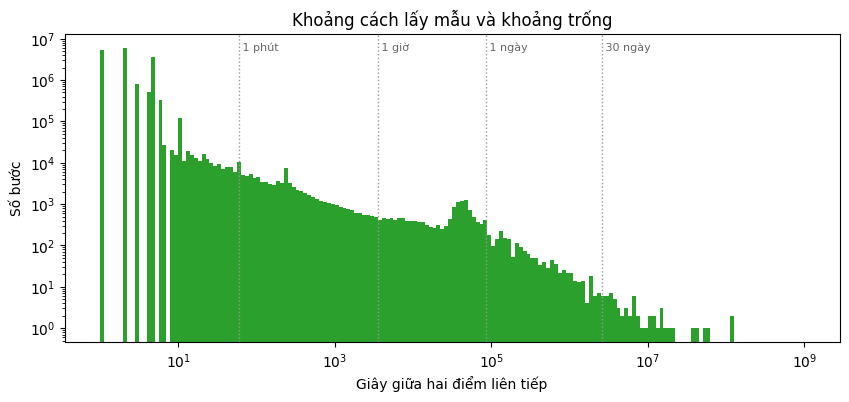

In [2]:
display(qtable(A["dt_q"], A["dt_max"], "dt_s"))

fig, ax = plt.subplots(figsize=(10, 4))
ax.stairs(A["dt_hist"], DT_BINS, fill=True, color="#2ca02c")
ax.set_xscale("log"); ax.set_yscale("log")
for sec, label in ((60, "1 phút"), (3600, "1 giờ"), (86400, "1 ngày"), (30 * 86400, "30 ngày")):
    ax.axvline(sec, color="#999", ls=":", lw=1)
    ax.text(sec, ax.get_ylim()[1] * 0.4, f" {label}", fontsize=8, color="#666")
ax.set_xlabel("Giây giữa hai điểm liên tiếp")
ax.set_ylabel("Số bước")
ax.set_title("Khoảng cách lấy mẫu và khoảng trống")
plt.show()


Theo user: khoảng cách lấy mẫu điển hình (trung vị) và tỷ lệ bước đúng 1, 2, 5 giây.

In [3]:
display(users["median_dt_s"].round().value_counts().sort_index().rename("số user").to_frame().T)
users[["share_dt_1s", "share_dt_2s", "share_dt_5s"]].describe().round(3)

median_dt_s,1.0,2.0,3.0,4.0,5.0,12.0,16.0,17.0,19.0,20.0,21.0,24.0,25.0,50.0,53.0,54.0,62.0,63.0,72.0,74.0,75.0,76.0
số user,20,30,11,4,29,2,2,4,2,3,2,1,2,1,1,2,1,1,1,1,1,1


,share_dt_1s,share_dt_2s,share_dt_5s
count,122.000,122.000,122.000
mean,0.197,0.196,0.271
std,0.307,0.275,0.334
min,0.000,0.000,0.000
25%,0.000,0.009,0.011
50%,0.003,0.072,0.080
75%,0.344,0.222,0.402
max,0.997,0.989,0.982


## 5. Tốc độ giữa hai điểm liên tiếp

**Câu hỏi:** tốc độ phân bố thế nào, và có chỗ nào phân phối bị gãy giữa di chuyển bình thường và giá trị bất thường không?

Tốc độ chỉ phản ánh di chuyển khi hai điểm đủ gần nhau về thời gian. Notebook không chọn trước dt tối đa: số liệu được lưu dạng histogram hai chiều dt × tốc độ, nên có thể xem phân phối tốc độ ở nhiều mức dt (`DT_CUTS_S`).

**Cách đọc:** nếu các đường của các mức dt gần trùng nhau ở vùng tốc độ cao, vùng đó không phụ thuộc lựa chọn dt. Chỗ phân phối bị gãy (vùng trũng) là nơi ít bước sát ngưỡng nhất nếu sau này đặt ngưỡng lọc. Phân vị và đường phân phối chỉ tính các bước có tốc độ > 0 (thang log không chứa 0), nên khác với phân vị tính trên mọi bước; bảng đếm theo mốc tốc độ ở cell sau thì đếm chính xác trên mọi bước. Các vạch xám là tốc độ tham chiếu (đi bộ, cao tốc, máy bay), không phải ngưỡng.


,10 giây,1 phút,5 phút,30 phút,2 giờ,không giới hạn
"tốc độ (km/h), dt ≤",,,,,,
p50,18.8,18.8,18.8,18.8,18.8,18.8
p90,84.1,84.1,84.1,84.1,84.1,84.1
p95,105.9,105.9,105.9,105.9,105.9,105.9
p99,149.6,149.6,149.6,149.6,149.6,149.6
p99.9,841.4,841.4,841.4,841.4,841.4,841.4


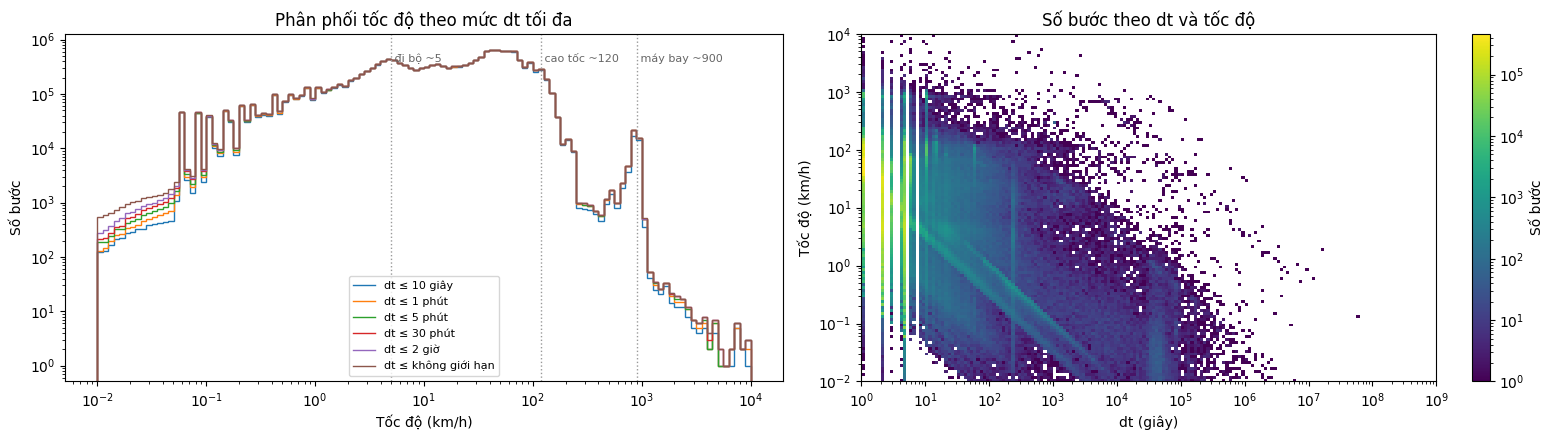

In [4]:
H2 = A["dt_sp_hist"]                       # [ô dt, ô tốc độ]
DT_UPPER = DT_BINS[1:]


def speed_hist_upto(cut_s):
    """Histogram tốc độ của các bước có dt ≤ cut_s (xấp xỉ theo biên trên của ô dt)."""
    return H2[DT_UPPER <= cut_s * 1.0001].sum(axis=0)


qt = pd.DataFrame({fmt_s(c): [hist_quantile(speed_hist_upto(c), SPEED_BINS, q) for q in QUANTILES]
                   for c in DT_CUTS_S}, index=[f"p{q * 100:g}" for q in QUANTILES])
qt.index.name = "tốc độ (km/h), dt ≤"
display(qt.round(1))

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
ax = axes[0]
for c in DT_CUTS_S:
    ax.stairs(speed_hist_upto(c), SPEED_BINS, label=f"dt ≤ {fmt_s(c)}")
ax.set_xscale("log"); ax.set_yscale("log")
for v_, lab in ((5, "đi bộ ~5"), (120, "cao tốc ~120"), (900, "máy bay ~900")):
    ax.axvline(v_, color="#999", ls=":", lw=1)
    ax.text(v_, ax.get_ylim()[1] * 0.3, f" {lab}", color="#666", fontsize=8)
ax.set_xlabel("Tốc độ (km/h)"); ax.set_ylabel("Số bước")
ax.set_title("Phân phối tốc độ theo mức dt tối đa")
ax.legend(fontsize=8)

ax = axes[1]
im = ax.pcolormesh(DT_BINS, SPEED_BINS, np.ma.masked_equal(H2, 0).T, norm=LogNorm(), cmap="viridis")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("dt (giây)"); ax.set_ylabel("Tốc độ (km/h)")
ax.set_title("Số bước theo dt và tốc độ")
plt.colorbar(im, ax=ax, label="Số bước")
plt.tight_layout()
plt.show()


In [5]:
cm = pd.DataFrame(A["cut_mark"].T, index=pd.Index(SPEED_MARKS, name="tốc độ > (km/h)"),
                  columns=[f"dt ≤ {fmt_s(c)}" for c in DT_CUTS_S])
print("Số bước vượt từng mốc tốc độ (đếm chính xác):")
display(cm)
print("Tỷ lệ % trên số bước có dt ≤ mức tương ứng:")
(cm / A["n_le_cut"] * 100).round(3)


Số bước vượt từng mốc tốc độ (đếm chính xác):


,dt ≤ 10 giây,dt ≤ 1 phút,dt ≤ 5 phút,dt ≤ 30 phút,dt ≤ 2 giờ,dt ≤ không giới hạn
tốc độ > (km/h),,,,,,
50,3961541,3984214,3987440,3988155,3988278,3988415
100,974444,983574,984439,984800,984869,984954
150,192021,193818,194096,194274,194315,194389
200,74485,75355,75553,75694,75726,75789
250,51550,52102,52231,52353,52384,52443
300,50220,50690,50793,50882,50911,50956
350,48998,49420,49510,49543,49572,49608
400,48240,48631,48711,48741,48769,48799
500,46629,46965,47034,47058,47084,47105


Tỷ lệ % trên số bước có dt ≤ mức tương ứng:


,dt ≤ 10 giây,dt ≤ 1 phút,dt ≤ 5 phút,dt ≤ 30 phút,dt ≤ 2 giờ,dt ≤ không giới hạn
tốc độ > (km/h),,,,,,
50,23.883,23.769,23.706,23.682,23.675,23.657
100,5.875,5.868,5.853,5.848,5.846,5.842
150,1.158,1.156,1.154,1.154,1.153,1.153
200,0.449,0.450,0.449,0.449,0.450,0.450
250,0.311,0.311,0.311,0.311,0.311,0.311
300,0.303,0.302,0.302,0.302,0.302,0.302
350,0.295,0.295,0.294,0.294,0.294,0.294
400,0.291,0.290,0.290,0.289,0.289,0.289
500,0.281,0.280,0.280,0.279,0.279,0.279


User có nhiều bước trên 1.000 km/h và 2.000 km/h (nhanh hơn máy bay thương mại). Đây là nơi nên xem bản đồ để hiểu kiểu lỗi.


In [6]:
users.nlargest(10, "n_speed_gt_1000")[["user", "n_steps", "n_speed_gt_1000", "n_speed_gt_2000"]]


,user,n_steps,n_speed_gt_1000,n_speed_gt_2000
87,128,1208308,174,11
96,144,582832,163,25
53,082,172542,162,2
5,010,931814,79,2
15,025,629890,20,14
105,153,2156963,18,3
44,068,937875,16,4
0,002,248213,13,4
26,041,1057037,13,6
27,042,239371,11,2


## 6. Khoảng trống thời gian

**Câu hỏi:** bước có dt lớn (tắt máy, mất tín hiệu, giữa hai chuyến đi) dài bao lâu và nhiều đến mức nào? Số khoảng trống thay đổi thế nào qua các mốc độ dài?


In [7]:
tbl = pd.DataFrame({"mốc_phút": GAP_MARKS_MIN, "số_bước_dài_hơn": A["gap_cnt"]})
tbl["tỷ_lệ_%_số_bước"] = tbl["số_bước_dài_hơn"] / A["n_steps"] * 100
tbl["giảm_so_với_mốc_trước"] = (-tbl["số_bước_dài_hơn"].diff()).fillna(0).astype(int)
display(tbl.set_index("mốc_phút").round(3))

per_day = pd.DataFrame({f"> {m} phút": users[f"n_gap_gt_{m}min"] / users["n_days"].clip(lower=1)
                        for m in GAP_MARKS_MIN})
print("Số khoảng trống mỗi ngày có dữ liệu, phân phối theo user:")
per_day.describe(percentiles=[0.25, 0.5, 0.75]).round(2).T


,số_bước_dài_hơn,tỷ_lệ_%_số_bước,giảm_so_với_mốc_trước
mốc_phút,,,
5,39094,0.232,0
10,28123,0.167,10971
30,19099,0.113,9024
60,15756,0.093,3343
180,11607,0.069,4149
360,9673,0.057,1934
720,5753,0.034,3920
1440,1933,0.011,3820


Số khoảng trống mỗi ngày có dữ liệu, phân phối theo user:


,count,mean,std,min,25%,50%,75%,max
> 5 phút,122.0,5.12,3.10,0.0,3.34,4.43,6.88,22.67
> 10 phút,122.0,3.46,1.83,0.0,2.36,3.01,4.30,12.00
> 30 phút,122.0,2.11,0.89,0.0,1.58,2.01,2.50,5.00
> 60 phút,122.0,1.71,0.65,0.0,1.41,1.64,2.06,3.68
> 180 phút,122.0,1.21,0.45,0.0,1.00,1.25,1.45,2.27
> 360 phút,122.0,1.00,0.36,0.0,0.84,1.05,1.23,1.63
> 720 phút,122.0,0.65,0.26,0.0,0.60,0.72,0.82,1.00
> 1440 phút,122.0,0.32,0.20,0.0,0.15,0.34,0.46,0.83


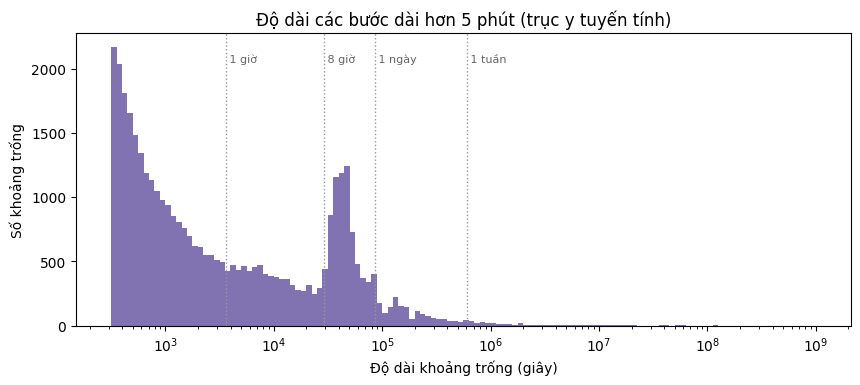

In [8]:
mask = DT_BINS[:-1] >= GAP_MARKS_MIN[0] * 60
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.stairs(A["dt_hist"][mask], DT_BINS[np.r_[mask, True]], fill=True, color="#8172b2")
ax.set_xscale("log")
for sec, label in ((3600, "1 giờ"), (8 * 3600, "8 giờ"), (86400, "1 ngày"), (7 * 86400, "1 tuần")):
    ax.axvline(sec, color="#999", ls=":", lw=1)
    ax.text(sec, ax.get_ylim()[1] * 0.9, f" {label}", fontsize=8, color="#666")
ax.set_xlabel("Độ dài khoảng trống (giây)")
ax.set_ylabel("Số khoảng trống")
ax.set_title(f"Độ dài các bước dài hơn {GAP_MARKS_MIN[0]} phút (trục y tuyến tính)")
plt.show()


## 7. Nhãn phương tiện (`labels.txt`)

**Câu hỏi:** với các đoạn đã có nhãn, tốc độ thật của từng phương tiện nằm ở đâu? Vùng tốc độ nào tách được phương tiện mặt đất (kể cả tàu) với máy bay? Mục này kiểm tra chéo vùng trũng thấy ở mục 5.

Theo User Guide, thời gian trong `labels.txt` đã được đổi sang GMT. Kiểm tra: nếu tốc độ đi bộ (`walk`) có trung vị khoảng 3–6 km/h thì nhãn khớp với quỹ đạo; nếu lệch hẳn, nhãn đang lệch giờ.

Tốc độ tính trên mọi bước nằm trong khoảng thời gian của nhãn. Phân vị tính xấp xỉ từ histogram.


In [9]:
names = [str(x) for x in A["mode_names"]]
H = A["mode_hist"]
mt = modes.set_index("mode").loc[names].copy()
for q in (0.5, 0.95, 0.99, 0.999):
    mt[f"p{q * 100:g}_km_h"] = [hist_quantile(H[i], SPEED_BINS, q) for i in range(len(names))]
mt.sort_values("hours", ascending=False).round(2)


,n_labels,hours,n_steps,p50_km_h,p95_km_h,p99_km_h,p99.9_km_h
mode,,,,,,,
walk,2666,1938.01,746624,4.22,14.96,37.58,133.35
car,777,1121.47,429345,29.85,94.41,105.93,211.35
bike,1101,954.14,511006,10.59,23.71,37.58,94.41
bus,1378,710.88,651963,16.79,59.57,94.41,118.85
train,169,377.12,446102,94.41,167.88,211.35,237.14
subway,470,246.43,169575,29.85,74.99,94.41,167.88
taxi,401,218.68,153190,29.85,74.99,105.93,118.85
airplane,13,32.49,7592,749.89,841.40,944.06,944.06
boat,6,4.27,3455,3.76,74.99,74.99,84.14


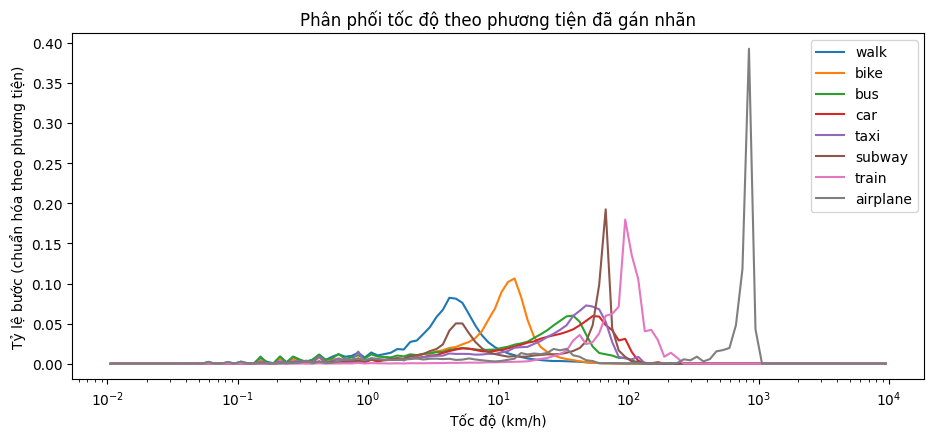

In [10]:
show = [m for m in ["walk", "bike", "bus", "car", "taxi", "subway", "train", "airplane"] if m in names]
centers = np.sqrt(SPEED_BINS[:-1] * SPEED_BINS[1:])
fig, ax = plt.subplots(figsize=(11, 4.5))
for m in show:
    h = H[names.index(m)]
    if h.sum() > 0:
        ax.plot(centers, h / h.sum(), label=m)
ax.set_xscale("log")
ax.set_xlabel("Tốc độ (km/h)")
ax.set_ylabel("Tỷ lệ bước (chuẩn hóa theo phương tiện)")
ax.set_title("Phân phối tốc độ theo phương tiện đã gán nhãn")
ax.legend()
plt.show()
